# Tutorial 2 — Building a training set with SHARC

A machine-learning potential is only as good as its training data. In this tutorial
we build a complete excited-state data set for **SO2** with 4 singlets and 3 triplets:
energies, forces, NACs, spin–orbit couplings and dipoles.

As the "quantum chemistry" we use SHARC's **linear vibronic coupling (LVC)** model of
SO2 (shipped with SHARC in `examples/SHARC_LVC`). An LVC model expands the diabatic
Hamiltonian to first order in the normal-mode displacements; it is cheap (a
millisecond per geometry) but has everything an ab initio method gives SHARC. In a
real project you replace it by your electronic-structure method (MOLCAS, ORCA,
Turbomole, ... through SHARC's interfaces); everything else stays the same.

You will learn

1. how to check your SOC data against the Wigner–Eckart form (and what to do if it fails);
2. how to sample geometries: Wigner distribution and snapshots from dynamics;
3. what SHARC returns for every geometry (`h`, `grad`, `nacdr`, `dm`) and in which units;
4. how to turn that into X-MACE labels (`mace.data.sharc_labels`);
5. how to look at and check a data set before training.

**Requirements:** SHARC 4 with pysharc, `$SHARC` pointing to SHARC's `bin`
directory (`source $SHARC/sharcvars.sh`). Runtime: about 5 minutes.

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase.io
import matplotlib.pyplot as plt
import numpy as np

import mace  # noqa: F401

TUTORIAL = Path.cwd()
sys.path.insert(0, str(TUTORIAL / "tools"))
import so2_lvc as lvc  # helpers for this tutorial series

WORK = TUTORIAL / "work"
WORK.mkdir(exist_ok=True)
np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({"figure.dpi": 100})

root = lvc.sharc_root()
if root is None:
    raise RuntimeError("Set $SHARC to SHARC's bin directory (source $SHARC/sharcvars.sh)")
print("SHARC found in", root)

SHARC found in <sharc>


## 1. The reference model and a first look at its SOCs

`make_lvc_model` copies SHARC's SO2 model (`V0.txt` with the geometry, frequencies and
normal modes; `LVC.template` with the LVC parameters) into `work/lvc_model`.

Before generating any data, always check that the SOC matrices of your method have
the Wigner–Eckart form that X-MACE's `--soc_mode=spin_orbit` assumes (Tutorial 1,
section 6). For SHARC's example template the check **fails**:

In [2]:
info = lvc.make_lvc_model(WORK / "lvc_model")
print(f"relative residual of SHARC's example SOC matrix: {info['original_residual']:.2f}")

relative residual of SHARC's example SOC matrix: 0.93


A residual of 0.93 means that almost none of the matrix can be written as
$\mathbf a_{IJ} \cdot$ (spin tensor). Looking at the template shows why: its SOC
matrix is real and symmetric, but for real spin-free states the singlet–triplet
$M_S = 0$ elements must be purely imaginary ($\propto i\,a_z$). This example matrix
is a placeholder, not a physical SOC matrix.

What to do in such a case:

* **SOCs from a quantum-chemistry code via SHARC** (MOLCAS, MOLPRO, ADF, ... `QM.out`
  or `output.dat`): these are in SHARC's convention and fit to machine precision —
  use `--soc_mode=spin_orbit`.
* **SOCs in another convention** (another state order, $M_S$ basis or phase): convert
  them to SHARC order first; the residual tells you when you got it right.
* **SOCs you cannot convert** (e.g. only magnitudes): train them with
  `--soc_mode=free`, which learns any list of numbers per frame (Tutorial 6).

For this tutorial `make_lvc_model` replaced the SOC block by the closest physical one:
one coupling vector per pair fitted to the original matrix and rescaled to the same
coupling strength, written as `SOC R` and `SOC I` blocks. Its residual is zero, as
we will see below.

In [3]:
v0 = lvc.read_v0(WORK / "lvc_model" / "V0.txt")
print("atoms:", v0["symbols"])
print("geometry (bohr):\n", v0["coords"])
print("vibrational frequencies (cm-1):", (v0["frequencies"][v0["frequencies"] > 0] * 219474.63).round(1))

atoms: ['S', 'O', 'O']
geometry (bohr):
 [[ 0.      0.     -0.0004]
 [ 0.     -2.3836  1.3616]
 [ 0.      2.3836  1.3616]]
vibrational frequencies (cm-1): [ 518.8 1165.2 1405.2]


## 2. Sampling geometries

The training set has to cover every geometry the dynamics will visit, in all the
electronic states. We combine three sources:

1. **Wigner sampling** around the minimum: the quantum-mechanical distribution of
   positions and momenta in the vibrational ground state. This is also how SHARC's
   `wigner.py` creates initial conditions. For a normal mode with angular frequency
   $\omega$, the mass-weighted coordinate $Q$ and momentum $P$ are Gaussian with
   variances $1/(2\omega)$ and $\omega/2$ (atomic units);
2. a **widened** Wigner distribution (1.6 × the width), for larger distortions;
3. **snapshots from excited-state dynamics** with the reference method. After
   excitation the molecule moves away from the ground-state geometry, to regions
   neither 1 nor 2 covers well.

In a real project, step 3 is usually replaced by **active learning**: run dynamics
with a preliminary model, compute reference data where a committee of models
disagrees, retrain (Tutorial 6).

In [4]:
wigner = lvc.wigner_sample(v0, 250, seed=0)
wide = lvc.wigner_sample(v0, 150, seed=1, spread=1.6)
initial = lvc.wigner_sample(v0, 8, seed=2)  # initial conditions for 8 trajectories
print("geometries:", wigner["coords"].shape, "velocities:", wigner["velocities"].shape)

geometries: (250, 3, 3) velocities: (250, 3, 3)


Now run 8 short surface-hopping trajectories with the LVC model and pysharc,
starting in the first excited singlet (MCH state 2). `write_trajectory` writes the
files SHARC needs (`input`, `geom`, `veloc`, and the interface files in `QM/`) —
open `work/lvc_data_traj/TRAJ_0/input` to see them. Tutorial 5 explains them in
detail. This takes about 3 minutes.

In [5]:
import time

lvc_files = {name: (WORK / "lvc_model" / name).read_text() for name in ("LVC.template", "V0.txt", "LVC.resources")}
snapshots = []
start = time.time()
for i in range(8):
    directory = lvc.write_trajectory(
        WORK / "lvc_data_traj" / f"TRAJ_{i}",
        initial["coords"][i], initial["velocities"][i], v0["masses"], lvc_files,
        tmax=100.0, stepsize=0.5, state=2, seed=100 + i,
    )
    lvc.run_pysharc(directory, "LVC")
    frames = ase.io.read(directory / "output.xyz", "::4")  # every 2 fs
    snapshots.append(np.array([f.positions for f in frames]) / lvc.BOHR_TO_ANGSTROM)
print(f"{len(snapshots)} trajectories in {time.time() - start:.0f} s")
snapshots = np.concatenate(snapshots)

coords = np.concatenate([wigner["coords"], wide["coords"], snapshots])
source = np.array(["Wigner"] * 250 + ["wide Wigner"] * 150 + ["dynamics"] * len(snapshots))
print("geometries in total:", len(coords))

8 trajectories in 153 s
geometries in total: 808


How different are the three sources? Plot the two S–O bond lengths and the O–S–O
angle:

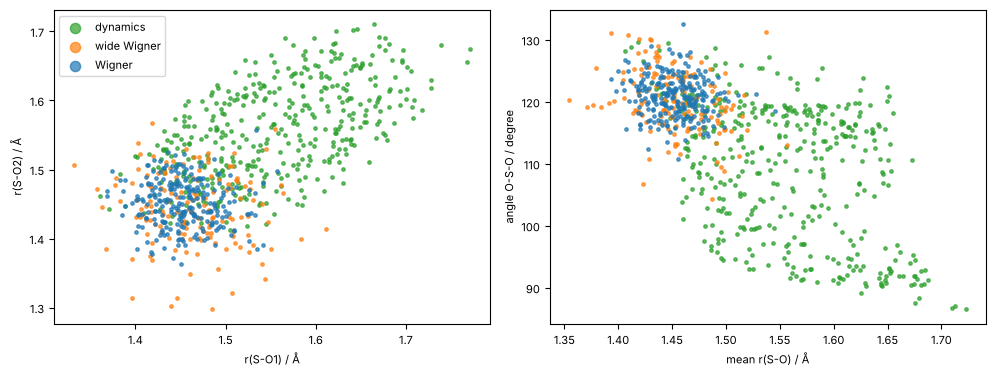

In [6]:
def internal(c):
    r1 = np.linalg.norm(c[:, 1] - c[:, 0], axis=1) * lvc.BOHR_TO_ANGSTROM
    r2 = np.linalg.norm(c[:, 2] - c[:, 0], axis=1) * lvc.BOHR_TO_ANGSTROM
    u, w = c[:, 1] - c[:, 0], c[:, 2] - c[:, 0]
    angle = np.degrees(np.arccos(np.sum(u * w, 1) / np.linalg.norm(u, axis=1) / np.linalg.norm(w, axis=1)))
    return r1, r2, angle


r1, r2, angle = internal(coords)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for name, color in (("dynamics", "C2"), ("wide Wigner", "C1"), ("Wigner", "C0")):
    sel = source == name
    axes[0].scatter(r1[sel], r2[sel], s=6, color=color, label=name, alpha=0.7)
    axes[1].scatter(0.5 * (r1[sel] + r2[sel]), angle[sel], s=6, color=color, alpha=0.7)
axes[0].set(xlabel="r(S-O1) / Å", ylabel="r(S-O2) / Å")
axes[1].set(xlabel="mean r(S-O) / Å", ylabel="angle O-S-O / degree")
axes[0].legend(markerscale=3)
plt.tight_layout()

The excited-state trajectories stretch the bonds and open the angle much more than
the ground-state Wigner distribution does — a model trained only on Wigner samples
would have to extrapolate there.

## 3. Reference calculations

`lvc_reference` runs SHARC's LVC interface on every geometry (in a separate process,
because SHARC's Python modules have very generic names such as `utils` and
`constants`). It returns exactly what SHARC writes to `QM.out`:

| key | shape | unit | meaning |
|---|---|---|---|
| `h` | `[nm, nm]` complex | Hartree | Hamiltonian in the MCH basis: energies on the diagonal, SOCs off it |
| `grad` | `[nm, n_atoms, 3]` | Hartree/bohr | gradient of every M_S state |
| `nacdr` | `[nm, nm, n_atoms, 3]` | 1/bohr | NACs between all M_S states |
| `dm` | `[3, nm, nm]` | e·bohr | dipole matrices (x, y, z) |

with nm = 4 + 3 × 3 = 13 M_S-resolved states.

In [7]:
start = time.time()
reference = lvc.lvc_reference(WORK / "lvc_model", coords)
print(f"{len(coords)} reference calculations in {time.time() - start:.1f} s")
for key, value in reference.items():
    print(f"{key:6s} {value.shape} {value.dtype}")

808 reference calculations in 2.6 s
h      (808, 13, 13) complex128
grad   (808, 13, 3, 3) float64
nacdr  (808, 13, 13, 3, 3) float64
dm     (808, 3, 13, 13) float64


Look at one Hamiltonian. The diagonal holds the energies; every triplet appears three
times (its M_S components), with identical energies. The off-diagonal elements are
the SOCs (about 10⁻⁴ Hartree ≈ 20 cm⁻¹):

energies (eV): [0.015 4.207 4.567 8.373 3.355 4.173 4.317 3.355 4.173 4.317 3.355 4.173 4.317]


largest Wigner-Eckart residual over the data set: 2.9e-16


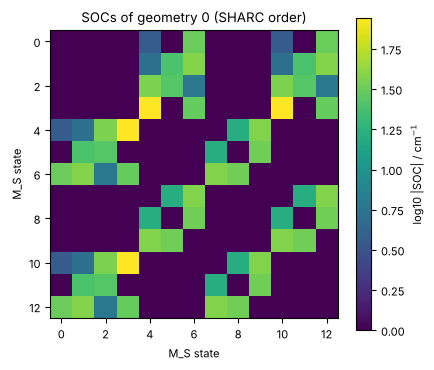

In [8]:
h = reference["h"][0]
print("energies (eV):", (np.diag(h).real * 27.211386).round(3))
fig, ax = plt.subplots(figsize=(4.4, 3.8))
image = ax.imshow(np.log10(np.abs(h - np.diag(np.diag(h))) * 219474.63 + 1e-3), cmap="viridis", vmin=0)
fig.colorbar(image, label="log10 |SOC| / cm$^{-1}$")
ax.set(title="SOCs of geometry 0 (SHARC order)", xlabel="M_S state", ylabel="M_S state")
plt.tight_layout()

from mace.modules.spin_states import soc_vectors_from_matrix

residuals = [soc_vectors_from_matrix(m - np.diag(np.diag(m)), lvc.STATES)[1] for m in reference["h"]]
print(f"largest Wigner-Eckart residual over the data set: {max(residuals):.1e}")

## 4. From SHARC quantities to X-MACE labels

X-MACE learns one energy, one force field and one permanent dipole per **spatial**
state, one NAC and one transition dipole per **same-multiplicity pair**, and the SOC
matrix (from which it fits one coupling vector per spin–orbit pair). The function
`mace.data.sharc_labels.labels_from_sharc` does the conversion:

* checks that the M_S components of every state are degenerate (i.e. `h` really is
  in the spin-free MCH basis);
* converts units: energies to eV, forces (= −gradient) to eV/Å, NACs to 1/Å,
  dipoles to e·Å, SOCs to cm⁻¹ (or eV, Hartree);
* keeps the NACs and transition dipoles of the same-multiplicity pairs, in the order
  (0,1), (0,2), ..., the same order the model uses.

`atoms_from_sharc` wraps the result in an `ase.Atoms` object with the keys X-MACE
reads by default (`REF_energy`, `REF_forces`, `REF_nacs`, `REF_socs`, `REF_dipoles`).

In [9]:
from mace.data.sharc_labels import atoms_from_sharc, labels_from_sharc

labels = labels_from_sharc(lvc.STATES, reference["h"][0], reference["grad"][0], reference["nacdr"][0], reference["dm"][0], soc_unit="cm-1")
for key, value in labels.items():
    print(f"{key:9s} shape {np.shape(value)}")
print("energies (eV):", labels["energies"].round(3))

frames = [
    atoms_from_sharc(lvc.SYMBOLS, c, lvc.STATES, reference["h"][k], reference["grad"][k],
                     reference["nacdr"][k], reference["dm"][k], soc_unit="cm-1")
    for k, c in enumerate(coords)
]
for k, atoms in enumerate(frames):
    atoms.info["source"] = str(source[k])
print({key: np.shape(value) for key, value in frames[0].info.items()})

energies  shape (7,)
socs      shape (13, 13)
forces    shape (3, 7, 3)
nacs      shape (3, 9, 3)
dipoles   shape (16, 3)
energies (eV): [0.015 4.207 4.567 8.373 3.355 4.173 4.317]


{'REF_energy': (7,), 'REF_forces': (3, 7, 3), 'REF_nacs': (3, 9, 3), 'REF_socs': (156,), 'REF_dipoles': (16, 3), 'source': ()}


Two details:

* **SOCs** are stored as the upper triangle of the complex 13 × 13 matrix, real and
  imaginary parts interleaved: 13·12 = 156 numbers. Extended XYZ files cannot store
  complex numbers; X-MACE accepts this layout as well as complex matrices and other
  layouts (see XMACE.md).
* **NACs** are raw NACs here. X-MACE turns them into smooth NACs with the reference
  energies of the same frame (`--nacs_format=raw`, the default for keys without
  "smooth" in their name).

## 5. Look at the data before training

A few plots catch most problems (wrong units, missing states, unconverged
calculations).

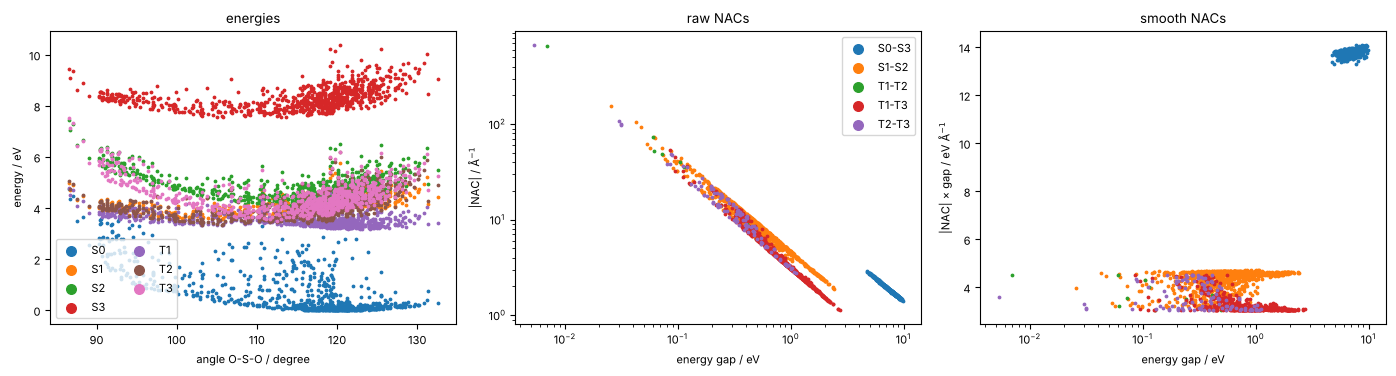

In [10]:
from mace.modules.spin_states import same_multiplicity_pairs

E = np.array([a.info["REF_energy"] for a in frames])
names = ["S0", "S1", "S2", "S3", "T1", "T2", "T3"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for s in range(7):
    axes[0].scatter(angle, E[:, s], s=3, label=names[s], color=f"C{s}")
axes[0].set(xlabel="angle O-S-O / degree", ylabel="energy / eV", title="energies")
axes[0].legend(markerscale=4, fontsize=8, ncol=2)

pairs = same_multiplicity_pairs(lvc.STATES)
N = np.array([a.info["REF_nacs"] for a in frames])  # [frames, atoms, pairs, 3]
gaps = np.array([[abs(e[j] - e[i]) for i, j in pairs] for e in E])
norm = np.linalg.norm(N, axis=(1, 3))
for p, (i, j) in enumerate(pairs):
    coupled = norm[:, p] > 1e-6  # LVC: some pairs are not coupled by any mode (zero NACs)
    if coupled.any():
        axes[1].scatter(gaps[coupled, p], norm[coupled, p], s=3, label=f"{names[i]}-{names[j]}")
        axes[2].scatter(gaps[coupled, p], norm[coupled, p] * gaps[coupled, p], s=3)
axes[1].set(xscale="log", yscale="log", xlabel="energy gap / eV", ylabel="|NAC| / Å$^{-1}$", title="raw NACs")
axes[2].set(xscale="log", xlabel="energy gap / eV", ylabel="|NAC| × gap / eV Å$^{-1}$", title="smooth NACs")
axes[1].legend(markerscale=4, fontsize=8)
plt.tight_layout()

* The singlet and triplet manifolds overlap between 3 and 6 eV, where intersystem
  crossing can happen.
* The raw NACs grow like 1/gap (a straight line of slope −1 on the log–log plot) and
  reach hundreds of Å⁻¹; the smooth NACs stay bounded. In an LVC model the smooth NACs
  are almost constant (the coupling constants λ); in ab initio data they vary more.
  Pairs that no vibrational mode couples have zero NACs and are not plotted.

Before writing the files, run the same checks X-MACE runs at the start of training:
`standardise_excited_configs` converts the labels to the model's layout, fits the
SOC vectors and counts the frames per label. A warning here would appear in the
training log too.

In [11]:
from mace import data
from mace.data.excited import ExcitedStateSpec, standardise_excited_configs

spec = ExcitedStateSpec(n_states=7, n_nacs=len(pairs), n_dipoles=7 + len(pairs), states=lvc.STATES, soc_mode="spin_orbit")
print(spec.describe())
keyspec = data.KeySpecification(  # what --energy_key, --forces_key, ... set up
    info_keys={"energy": "REF_energy", "socs": "REF_socs", "dipoles": "REF_dipoles"},
    arrays_keys={"forces": "REF_forces", "nacs": "REF_nacs"},  # also found in atoms.info
)
configs = [data.config_from_atoms(a, key_specification=keyspec) for a in frames[:50]]
print("frames per label:", standardise_excited_configs(configs, spec))
print("SOC vectors of frame 0 (cm-1):\n", configs[0].properties["soc_vectors"].round(2))

7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=15 coupling vectors (spin_orbit), dipoles=16
frames per label: {'energy': 50, 'forces': 50, 'nacs': 50, 'socs': 50, 'dipoles': 50}
SOC vectors of frame 0 (cm-1):
 [[  0.    -9.     0.  ]
 [ -0.     0.75  -0.  ]
 [ -0.    77.54  -0.  ]
 [ -0.    12.87   0.  ]
 [ -0.   -60.57   0.  ]
 [ -0.    93.96  -0.  ]
 [ -0.   -88.24   0.  ]
 [  0.    65.79  -0.  ]
 [  0.    14.49  -0.  ]
 [ -0.   215.1   -0.  ]
 [  0.     1.38   0.  ]
 [  0.    75.26  -0.  ]
 [ -0.   -22.84  -0.  ]
 [ -0.    52.85  -0.  ]
 [ -0.   -47.08  -0.  ]]


## 6. Train/test split and files

Keep a test set the model never sees during training (the validation set used for
early stopping is split off the training file by `--valid_fraction`). Shuffle first:
consecutive snapshots of a trajectory are strongly correlated.

In [12]:
rng = np.random.default_rng(0)
order = rng.permutation(len(frames))
test, train = [frames[k] for k in order[:150]], [frames[k] for k in order[150:]]
ase.io.write(WORK / "so2_train.xyz", train)
ase.io.write(WORK / "so2_test.xyz", test)
print(f"train: {len(train)} frames, test: {len(test)} frames")
print("first lines of the training file:")
print("".join(open(WORK / "so2_train.xyz").readlines()[:2])[:600], "...")

train: 658 frames, test: 150 frames
first lines of the training file:
3
Properties=species:S:1:pos:R:3 REF_energy="0.1977683211271131 4.151934215704222 4.6084379918334015 8.338526486897853 3.5711369776758444 4.072040147769308 4.176733288659322" REF_forces="_JSON [[[-0.0, 4.429207778945409, 2.1360761597366276], [-0.0, 2.5861303974098253, -4.846739726521287], [-0.0, 9.703620554483223, -4.763526471649379], [-0.0, 7.904266974213768, -6.6443965119636985], [-0.0, 5.029563467354988, -0.5521511450466042], [-0.0, 6.1236746119592755, -6.87736593553456], [-0.0, 7.2811657397678875, -6.895945923268683]], [[-0.0, -1.5134035615605848, 0.31387151609548014], [-0.0, -4.9360973391 ...


## Your own data

* **From SHARC calculations** (`QM.out` files of any SHARC interface): read them with
  SHARC's own reader inside SHARC's environment and call `atoms_from_sharc`:

  ```python
  from qmout import QMout          # SHARC's lib directory on PYTHONPATH
  q = QMout(filepath="QM.out")
  atoms = atoms_from_sharc(symbols, coords_bohr, states, q["h"], q["grad"], q["nacdr"], q["dm"])
  ```

* **From other codes**: write an extended XYZ file with, per frame, the energies of all
  states `[S]`, forces `[n_atoms, S, 3]`, NACs `[n_atoms, P, 3]` (for the
  same-multiplicity pairs, or for all pairs: X-MACE picks the right ones), SOC
  matrices in SHARC order and dipoles `[S + P, 3]`.
* **Phases** do not have to be consistent between frames.
* **Missing labels** are fine: a frame without NACs simply does not contribute to
  the NAC loss (Tutorial 6).

**Next:** [Tutorial 3](03_training.ipynb) trains X-MACE on this data.